# Ajuste de los tres mejores candidatos

| | |
|---|---|
| **Entrega** | PSet 3, sección 7 de `CD_PSet_3.pdf` (ajuste de hiperparámetros) |
| **Código** | `src/tuning.py` (Optuna) y `src/experimentos.py` (registro en MLflow) |
| **Datos** | solo entrenamiento; los mismos 7 pliegues `TimeSeriesSplit` de los candidatos |

**Sección 7 del PDF.** Ajusta los 3 mejores candidatos de la fase anterior:
- búsqueda con `RandomizedSearchCV`, Optuna o exhaustiva, justificando la elección;
- al menos 30 configuraciones por modelo, con el mismo esquema de CV;
- espacio de búsqueda definido y justificado (rangos y escala);
- cada configuración como corrida hija dentro de una corrida padre por modelo.

Se reporta cuánto mejoró cada modelo frente a su versión sin ajustar. Si la mejora es menor que la desviación entre
pliegues, no se considera mejora.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.datos import cargar
from src.pipeline import preparar, dividir, FEATURES, TARGET, pliegues
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True})
obt, metadata = cargar()
datos = preparar(obt)
train, holdout = dividir(datos)
print({'fuente': metadata['tabla'], 'sha256': metadata['sha256'], 'filas_obt': len(obt), 'entrenamiento': len(train), 'holdout_reservado': len(holdout)})

{'fuente': 'PORTAFOLIO_P3.OBT.OBT_ACCION_MES', 'sha256': 'c356891723976bceaa7447fe9682902ea520e46ad5bc9490ba43093a228f228f', 'filas_obt': 87178, 'entrenamiento': 46851, 'holdout_reservado': 11326}


## 7.1 Los tres mejores candidatos

Se eligen por la métrica técnica, el MAE de CV de `docs/candidatos.csv` (sección 6), entre los modelos que tienen
hiperparámetros. Quedan fuera las líneas base y los fundacionales: estos se usan en zero-shot y no tienen
hiperparámetros que ajustar con nuestros datos. Ajustarlos sería fine-tuning de pesos, que está fuera del alcance de
esta entrega.

In [2]:
from src.tuning import ESPACIOS
cand = pd.read_csv(ROOT / 'docs/candidatos.csv')
ajustables = cand[cand.modelo.isin(ESPACIOS)].sort_values('mae_cv_media')
display(ajustables[['modelo', 'familia', 'mae_cv_media', 'mae_cv_std', 'ic_media', 'negocio_sharpe_neto']].round(4))
MEJORES = ajustables.modelo.head(3).tolist()
print('Tres mejores por MAE de CV:', MEJORES)

,modelo,familia,mae_cv_media,mae_cv_std,ic_media,negocio_sharpe_neto
6,M4_ridge,lineal,0.0681,0.0200,-0.0319,0.1966
4,M3_lightgbm,boosting,0.0706,0.0223,-0.0009,0.4404
5,M3b_xgboost,boosting,0.0732,0.0202,-0.0042,0.4898
3,M2_random_forest,bagging,0.0757,0.0247,-0.0001,0.2014
7,M5_mlp,red_neuronal,0.0896,0.0189,-0.0177,0.2846


Tres mejores por MAE de CV: ['M4_ridge', 'M3_lightgbm', 'M3b_xgboost']


## 7.2 Método y espacio de búsqueda

**Optuna con muestreador TPE**, y no `RandomizedSearchCV` ni una búsqueda exhaustiva:
- Con 30 configuraciones y espacios de 4 a 9 dimensiones, una rejilla exhaustiva no cabe, y el muestreo aleatorio
  desperdicia pruebas. TPE concentra las siguientes en la zona donde el MAE fue mejor.
- Maneja en un solo espacio escalas logarítmicas, enteros y categorías (por ejemplo, la función de pérdida, o si se
  usa el rango transversal).
- Da las gráficas de historia y de importancia de hiperparámetros.
- **Objetivo:** el MAE medio de CV en los mismos 7 pliegues (decisión W3), sin poda: cada configuración se evalúa
  completa. Semilla 42.

**Espacio (`ESPACIOS` y `PREPARACION` en `src/tuning.py`):**

| Hiperparámetro | Rango | Escala | Por qué |
|---|---|---|---|
| `learning_rate` (boosting) | 0,005–0,2 | log | su efecto es multiplicativo |
| `n_estimators` | 50–1000 | log | importa el orden de magnitud |
| `num_leaves` / `max_depth` | 4–128 / 2–8 | log / lineal | complejidad de cada árbol; la señal es débil, así que árboles pequeños |
| `min_child_samples` / `min_child_weight` / `min_samples_leaf` | 20–2000 / 1–500 / 20–2000 | log | regularización por tamaño de hoja con ~40 mil filas |
| `subsample`, `colsample_bytree`, `max_features` | 0,1–1 | lineal | fracciones |
| `reg_lambda` / `alpha` (Ridge, MLP) | 1e-3–100 / 1e-3–1e5 / 1e-5–10 | log | regularización: su efecto es multiplicativo |
| pérdida (boosting) | L2, L1, Huber | categórica | el objetivo tiene colas gruesas (curtosis 9,6, EDA) |
| `k` de `SelectKBest` | 10, 20, 30, todas | categórica | 24 pares de predictores con \|ρ\| > 0,9 (EDA) |
| rango transversal | sí, no | categórica | el mes explica el 34,5 % de la varianza (EDA) |

## 7.3 Ejecución

Cada modelo se ajusta con `src/tuning.py`. Se puede correr en terminales separadas, un modelo en cada una, con
MLflow arriba y sin Kestra ni Spark:

```bash
uv run --group modelos python -m src.tuning --modelo <modelo> --trials 30
```

Cada corrida deja una corrida padre `tuning_<modelo>` con 30 hijas en MLflow, `docs/tuning_<modelo>.csv`, las
gráficas `docs/figuras/tuning_<modelo>_*.png` y un correo con el resumen. La celda siguiente las ejecuta desde el
notebook si `EJECUTAR = True`; si ya se corrieron en terminal, solo lee los resultados.

In [3]:
EJECUTAR = False      # True para correr aqui las 90 configuraciones (mas lento que en terminales separadas)
if EJECUTAR:
    from src.experimentos import datos_para_registro
    from src.tuning import ajustar
    tr, meta, riesgo, meta_dia = datos_para_registro()
    defecto = cand.set_index('modelo')
    for m in MEJORES:
        ajustar(m, tr, meta, riesgo, meta_dia, n_trials=30, por_defecto=defecto.loc[m, ['mae_cv_media', 'mae_cv_std']].to_dict())
faltan = [m for m in MEJORES if not (ROOT / f'docs/tuning_{m}.csv').exists()]
print('Resultados disponibles:', [m for m in MEJORES if m not in faltan], '| faltan:', faltan)

Resultados disponibles: ['M4_ridge', 'M3_lightgbm', 'M3b_xgboost'] | faltan: []


## 7.4 Resultados: ¿mejoró cada modelo?

In [4]:
filas = []
for m in MEJORES:
    ruta = ROOT / f'docs/tuning_{m}.csv'
    if not ruta.exists():
        continue
    t = pd.read_csv(ruta)
    mejor = t.sort_values('mae_cv_media').iloc[0]
    d = cand.set_index('modelo').loc[m]
    mejora = d.mae_cv_media - mejor.mae_cv_media
    filas.append({'modelo': m, 'configuraciones': len(t), 'mae_cv_defecto': d.mae_cv_media, 'desv_defecto': d.mae_cv_std,
                  'mae_cv_ajustado': mejor.mae_cv_media, 'desv_ajustado': mejor.mae_cv_std, 'mejora_mae': mejora,
                  'mejora_supera_desv': mejora > d.mae_cv_std, 'mae_train_ajustado': mejor.mae_train_cv,
                  'brecha_ajustado': mejor.brecha_mae, 'ic_ajustado': mejor.get('ic_media', np.nan),
                  'sharpe_ajustado': mejor.get('negocio_sharpe_neto', np.nan), 'run_id_mejor': mejor.run_id})
mejora = pd.DataFrame(filas).set_index('modelo')
mejora.to_csv(ROOT / 'docs/tuning_resumen.csv')
display(mejora.round(4))
lb = pd.read_csv(ROOT / 'docs/lineas_base.csv', index_col=0)['vara']
print(f"Vara: MAE de B1 {lb['MAE de B1 (menor es mejor)']:.4f}; Sharpe neto de B5 {lb['Sharpe neto de B5 (mayor es mejor)']:.2f}")
for m, f in mejora.iterrows():
    print(f"{m}: mejora {f.mejora_mae:+.4f} frente a una desviacion entre pliegues de {f.desv_defecto:.4f} -> "
          + ('ES mejora' if f.mejora_supera_desv else 'NO cuenta como mejora (menor que la desviacion)')
          + f"; supera a B1 en MAE: {f.mae_cv_ajustado < lb['MAE de B1 (menor es mejor)']}; "
          + f"supera a B5 en Sharpe: {f.sharpe_ajustado > lb['Sharpe neto de B5 (mayor es mejor)']}")

,configuraciones,mae_cv_defecto,desv_defecto,mae_cv_ajustado,desv_ajustado,mejora_mae,mejora_supera_desv,mae_train_ajustado,brecha_ajustado,ic_ajustado,sharpe_ajustado,run_id_mejor
modelo,,,,,,,,,,,,
M4_ridge,30,0.0681,0.0200,0.0636,0.0161,0.0045,False,0.0524,0.0112,-0.0063,0.4213,75f75a7030154008a54e502bf2e4d18b
M3_lightgbm,30,0.0706,0.0223,0.0636,0.0163,0.0070,False,0.0478,0.0157,0.0040,0.3019,f7596a565f8a458492057238f245cf89
M3b_xgboost,30,0.0732,0.0202,0.0640,0.0169,0.0092,False,0.0513,0.0127,-0.0089,0.2664,b3c5c84d6ef44b10a16ee01a7fd3d298


Vara: MAE de B1 0.0641; Sharpe neto de B5 0.54
M4_ridge: mejora +0.0045 frente a una desviacion entre pliegues de 0.0200 -> NO cuenta como mejora (menor que la desviacion); supera a B1 en MAE: True; supera a B5 en Sharpe: False
M3_lightgbm: mejora +0.0070 frente a una desviacion entre pliegues de 0.0223 -> NO cuenta como mejora (menor que la desviacion); supera a B1 en MAE: True; supera a B5 en Sharpe: False
M3b_xgboost: mejora +0.0092 frente a una desviacion entre pliegues de 0.0202 -> NO cuenta como mejora (menor que la desviacion); supera a B1 en MAE: True; supera a B5 en Sharpe: False


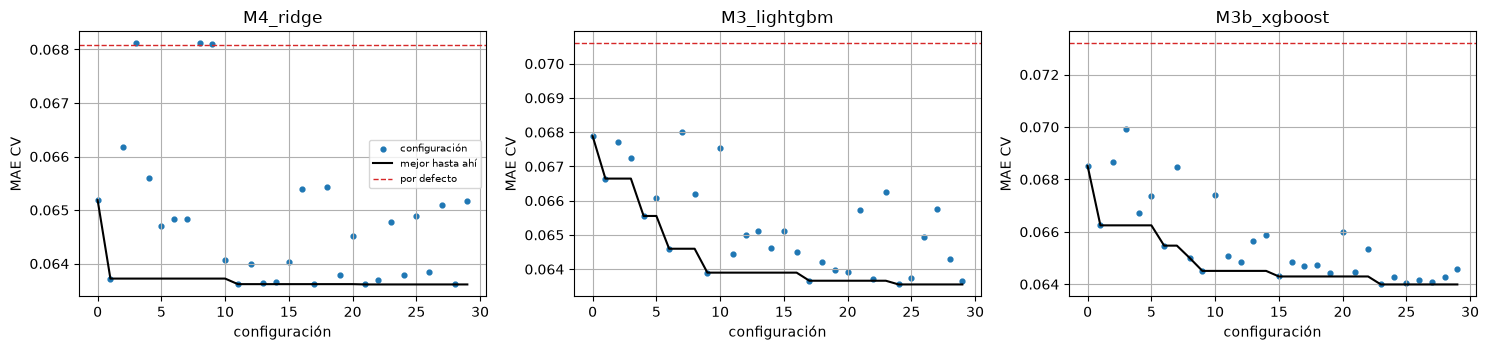

In [5]:
# Historia de cada busqueda: MAE de CV por configuracion y el mejor acumulado.
fig, ejes = plt.subplots(1, len(mejora), figsize=(5 * max(len(mejora), 1), 3.6), squeeze=False)
for ax, m in zip(ejes[0], mejora.index):
    t = pd.read_csv(ROOT / f'docs/tuning_{m}.csv').sort_values('trial')
    ax.scatter(t.trial, t.mae_cv_media, s=12, label='configuración')
    ax.plot(t.trial, t.mae_cv_media.cummin(), color='k', label='mejor hasta ahí')
    ax.axhline(mejora.loc[m, 'mae_cv_defecto'], color='tab:red', ls='--', lw=1, label='por defecto')
    ax.set_title(m); ax.set_xlabel('configuración'); ax.set_ylabel('MAE CV')
ejes[0][0].legend(fontsize=7); plt.tight_layout()
fig.savefig(ROOT / 'docs/figuras/tuning_historia.png', dpi=130, bbox_inches='tight'); plt.show()

**Lectura.** Con 30 configuraciones por modelo, los tres bajan su MAE de CV, pero **ninguna mejora supera la
desviación entre pliegues**, así que, según el criterio del PDF, no cuentan como mejora:

| Modelo | MAE por defecto | MAE ajustado | Mejora | Desviación entre pliegues | ¿Cuenta? |
|---|---|---|---|---|---|
| M4 Ridge | 0,0681 | 0,0636 | 0,0045 | 0,020 | no |
| M3 LightGBM | 0,0706 | 0,0636 | 0,0070 | 0,022 | no |
| M3b XGBoost | 0,0732 | 0,0640 | 0,0092 | 0,020 | no |

- Los tres ajustados quedan apenas por debajo de B1 (0,0641). La diferencia es menor a 0,0006, unas 30 veces más
  chica que la desviación entre pliegues: en la práctica **empatan con la media histórica**.
- En el negocio, ninguno ajustado supera a B5 en CV (Sharpe neto 0,42, 0,30 y 0,27 contra 0,54). El ajuste por MAE
  no se tradujo en mejores portafolios.
- La brecha entre entrenamiento y validación se mantiene acotada (0,011 a 0,016), así que el ajuste no llevó a
  sobreajuste.
- Para la sección 8 pasan los dos mejores por MAE de CV: **M3 LightGBM (0,06355)** y **M4 Ridge (0,06361)**.
